# 1. Introduction

Nama  : Muhammad Rafli Febriyanto

Batch : CODA RMT-015

Program ini dibuat untuk mengidentifikasi pola nasabah yang berpotensi keluar dengan meninjau beberapa aspek, yaitu kondisi demografis pelanggan, loyalitas dan pengalaman pelanggan, serta kondisi finansial guna mengetahui segmen nasabah yang paling berisiko keluar dan merancang strategi retensi yang lebih tepat sasaran untuk meningkatkan loyalitas serta profitabilitas jangka panjang.

Dataset : https://www.kaggle.com/datasets/radheshyamkollipara/bank-customer-churn

Tableau : https://public.tableau.com/app/profile/muhammad.rafli.febriyanto/viz/P1M2_Muhamad_Rafli_Febriyanto/Dashboard1?publish=yes

# 2. Identifikasi Masalah

## 2.1 Latar Belakang
Bank XYZ merupakan bank di Eropa yang menyediakan produk dan layanan perbankan seperti tabungan, kartu kredit, dan produk finansial lainnya. Dalam beberapa tahun terakhir, bank XYZ mengalami tingkat customer churn yang berdampak pada jumlah nasabah yang loyal dan penurunan profitabilitas secara keseluruhan. Mengingat biaya memperoleh nasabah baru lebih tinggi dibandingkan mempertahankan nasabah yang sudah ada, maka diperlukan analisis kondisi nasabah yang memiliki potensi besar untuk keluar. Dengan menganalisis data historis nasabah, perusahaan ingin mengidentifikasi pola perilaku dan karakteristik yang berkaitan dengan churn sehingga dapat memberikan strategi yang tepat untuk meningkatkan customer retention.

## 2.2 Kerangka Keja SMART
Mendefinisikan pernyataan masalah menggunakan Kerangka Kerja SMART :

1. Spesific (S) : Mengetahui churn rate dan menentukan segmen nasabah yang berisiko tinggi keluar (churn)
2. Measure (M) : Tingkat churn dapat dianalisis menggunakan persentase *Exited* berdasarkan variabel seperti age, gender, tenure, balance, dan lainnya.
3. Achievable (A) : Masalah dapat dianalisis menggunakan data historis nasabah melalui analisis statistik deskriptif dan inferal untuk mengidentifikasi pola serta hubungan antar variabel terhadap churn.
4. Relevant (R) : Mengidentifikasi faktor utama penyebab churn dapat menghasilkan strategi retensi yang lebih efektif dan meningkatkan profitabilitas jangka panjang.
5. Time-Bound (T) : Hasil analisis perlu diperoleh sebelum kuartal selanjutnya agar strategi retensi nasabah dapat segera diimplementasikan

**Problem Statment**

Bank XYZ ingin mengetahui customer churn rate dan mengidentifikasi pola perilaku nasabah berdasarkan demografis, engagement, dan finansial berdasarkan data historis nasabah sehingga dapat menentukan segmen yang berisiko tinggi dan merancang strategi retensi yang lebih aktif untuk kuartal selanjutnya.


## 2.3 Breaking Down the Problem

**Main Problem**

Bank XYZ belum mengetahui faktor apa saja yang secara signifikan memengaruhi customer churn (demografis, perilaku, dan finansial) serta membantu merancang pengembangan strategis untuk mengurangi churn dan meningkatkan customer retention.

**5W + 1H**
1. Nasabah mana yang memiliki risiko churn yang paling tinggi berdasarkan kondisi demografis ?
2. Seberapa besar jumlah produk / layanan yang dimiliki nasabah mempengaruhi tingkat churn ?
3. Tren churn rate seperti apa yang muncul seiring bertambahnya tenure nasabah ?
4. Apakah nasabah yang mengajukan komplain memiliki kecenderungan churn yang jauh lebih tinggi dibandingkan yang tidak ?
5. Bagaimana pengaruh nasabah yang keluar terhadap keuntungan bank ?
6. Apakah status keaktifan nasabah berpengaruh terhadap kemungkinan nasabah melakukan churn / keluar ?

# 3. Data Loading and Cleaning

In [1]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import skew, kurtosis
from scipy.stats import shapiro

In [3]:
df = pd.read_csv('customer-churn.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

Pada dataset ini, terdapat 10000 baris data (entri) dan terdiri dari 18 kolom yang berisikan data historis nasabah Bank XYZ. Pada dataset ini tidak ada null value, tetapi terdapat beberapa jenis data yang tidak sesuai dengan tipe datanya. Terdapat kolom "Row Number" dan "Surname" yang akan dihapus karena tidak digunakan pada analisis ini.

In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

**Remove Columns**

In [4]:
# Hapus kolom RowNumber dan Surname
df = df.drop(columns=['RowNumber', 'Surname'])
df.columns

Index(['CustomerId', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score',
       'Card Type', 'Point Earned'],
      dtype='object')

**Missing Values**

In [ ]:
# Cek nilai Null pada data
df.isnull().sum()

CustomerId            0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64

Tidak ada nilai null pada data ini

**Duplicate Data**

In [ ]:
# Cek nilai duplikat
df.duplicated().sum()

np.int64(0)

Tidak ada data duplikat pada data ini

**Inconsistent Data**

In [5]:
# Ubah tipe data kolom 'customer_id'  dari integer menjadi object
df['CustomerId'] = df['CustomerId'].astype('object')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerId          10000 non-null  object 
 1   CreditScore         10000 non-null  int64  
 2   Geography           10000 non-null  object 
 3   Gender              10000 non-null  object 
 4   Age                 10000 non-null  int64  
 5   Tenure              10000 non-null  int64  
 6   Balance             10000 non-null  float64
 7   NumOfProducts       10000 non-null  int64  
 8   HasCrCard           10000 non-null  int64  
 9   IsActiveMember      10000 non-null  int64  
 10  EstimatedSalary     10000 non-null  float64
 11  Exited              10000 non-null  int64  
 12  Complain            10000 non-null  int64  
 13  Satisfaction Score  10000 non-null  int64  
 14  Card Type           10000 non-null  object 
 15  Point Earned        10000 non-null  int64  
dtypes: fl

**Persebaran data target**

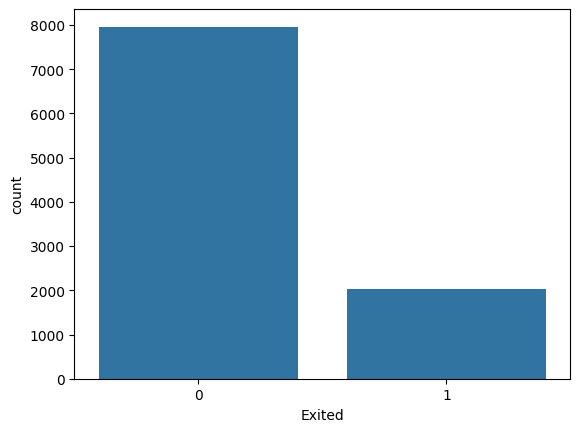

In [ ]:
sns.countplot(x='Exited', data=df)
plt.show()

Berdasarkan persebaran data target, data ini memiliki imbalanced class yang mana jumlah nasabah yang churn lebih sedikit dari total keseluruhan data sehingga diperlukan penanganan imbalanced data pada saat membuat model machine learning

# 4. EDA

In [ ]:
# Menghitung banyaknya nasabah yang sudah keluar (Churn) dan masih stay
# 0 = Stay, 1 = Keluar (Churn)
df['Exited'].value_counts().reset_index(name='Jumlah Nasabah')

,Exited,Jumlah Nasabah
0,0,7962
1,1,2038


Dari 10.000 data historis nasabah, sebanyak 2038 orang nasabah bank sudah keluar `

## 4.1 Nasabah mana yang memiliki risiko churn yang paling tinggi berdasarkan kondisi demografis ?

In [ ]:
# Gender
df_gender = (
    df.groupby('Gender')
      .agg(
          Total_Customer=('CustomerId', 'count'),
          Total_Churn=('Exited', 'sum'),
          Churn_Rate=('Exited', 'mean')
      )
      .reset_index()
)

df_gender['Churn_Rate'] = df_gender['Churn_Rate'] * 100

df_gender

,Gender,Total_Customer,Total_Churn,Churn_Rate
0,Female,4543,1139,25.071539
1,Male,5457,899,16.474253


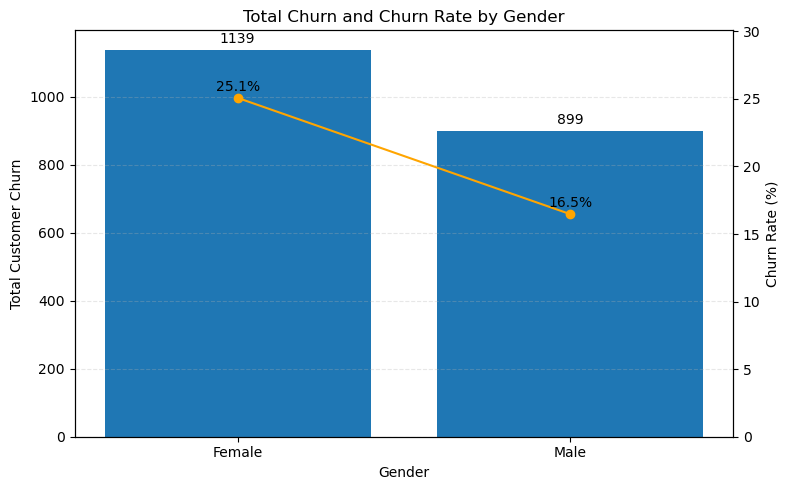

In [ ]:
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar Chart
bars = ax1.bar(
  df_gender['Gender'],
  df_gender['Total_Churn']
)

ax1.set_ylabel('Total Customer Churn')
ax1.set_xlabel('Gender')
ax1.set_title('Total Churn and Churn Rate by Gender')
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Line Chart
ax2 = ax1.twinx()

line = ax2.plot(
  df_gender['Gender'],
  df_gender['Churn_Rate'],
  marker='o',
  color='orange'
)

ax2.set_ylabel('Churn Rate (%)')

# Label

for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        f'{int(height)}',
        ha='center',
    )


for i, value in enumerate(df_gender['Churn_Rate']):
    ax2.text(
        i,
        value + 0.5,
        f'{value:.1f}%',
        ha='center',
    )
ax2.set_ylim(0, max(df_gender['Churn_Rate']) + 5)
plt.tight_layout()
plt.show()

Perempuan memiliki churn rate jauh lebih tinggi, artinya secara proporsi, nasabah **perempuan lebih rentan meninggalkan bank**. Kemungkinan penyebabnya kemungkinan produk kurang relevan, customer service kurang engaging, atau experience kurang sesuai ekspektasi.

**Rekomendasi**

Melakukan peningkatan marketing untuk meningkatkan retensi nasabah perempuan seperti :
- Cashback belanja
- Promo lifestyle (fashion, grocery, education)
- Program loyalty khusus perempuan

In [ ]:
# Membuat Interval umur
bins = [18, 30, 40, 50, 100]
labels = ['18-30', '31-40', '41-50', '51+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)

df_age = (
    df.groupby('AgeGroup')
      .agg(
          Total_Customer=('CustomerId', 'count'),
          Total_Churn=('Exited', 'sum'),
          Churn_Rate=('Exited', 'mean')
      )
      .reset_index()
)

df_age['Churn_Rate'] = df_age['Churn_Rate'] * 100

df_age

C:\Users\M Rafli F\App Data\Local\Temp\ipykernel_17152\873583451.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('AgeGroup')


,AgeGroup,Total_Customer,Total_Churn,Churn_Rate
0,18-30,1946,146,7.502569
1,31-40,4451,539,12.109638
2,41-50,2320,788,33.965517
3,51+,1261,563,44.647105


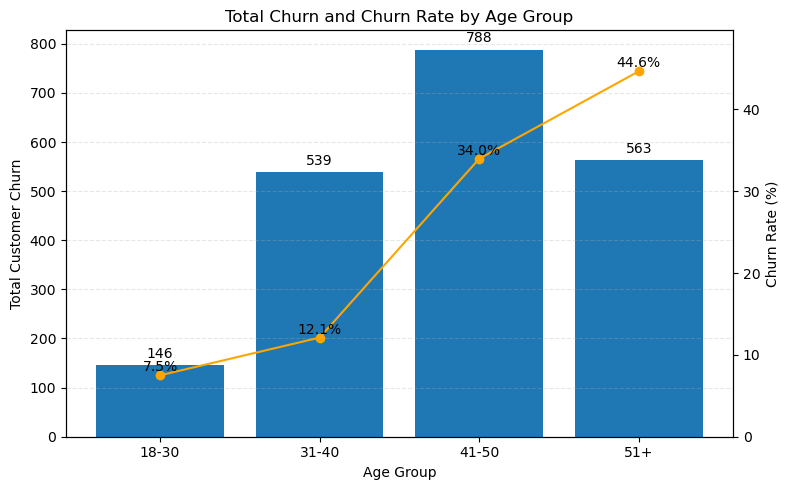

In [ ]:
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar Chart
bars = ax1.bar(
  df_age['AgeGroup'],
  df_age['Total_Churn']
)

ax1.set_ylabel('Total Customer Churn')
ax1.set_xlabel('Age Group')
ax1.set_title('Total Churn and Churn Rate by Age Group')
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Line Chart
ax2 = ax1.twinx()

line = ax2.plot(
  df_age['AgeGroup'],
  df_age['Churn_Rate'],
  marker='o',
  color='orange'
)

ax2.set_ylabel('Churn Rate (%)')

# Label

for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 15,
        f'{int(height)}',
        ha='center',
    )


for i, value in enumerate(df_age['Churn_Rate']):
    ax2.text(
        i,
        value + 0.5,
        f'{value:.1f}%',
        ha='center',
    )
ax2.set_ylim(0, max(df_age['Churn_Rate']) + 5)
plt.tight_layout()
plt.show()

Semakin tua usia maka semakin tinggi churn ratenya. **Kelompok usia yang paling berisiko, yaitu umur 41 - 50 (34%) dan 51+ (44.6%)**. Hal ini kemungkinan karena customer usia tua kurang nyaman dengan digital banking dan lebih sensitif terhadap services issues.

**Rekomendasi**
- Mengembangkan produk yang relevan pada usia tua seperti produk pensiun dan wealth managment.
- Melakukan edukasi tutorial penggunaan m-banking.
- Meningkatkan customer assistance atau prioritas untuk nasabah senior.

In [ ]:
df_country = (
    df.groupby('Geography')
      .agg(
          Total_Customer=('CustomerId', 'count'),
          Total_Churn=('Exited', 'sum'),
          Churn_Rate=('Exited', 'mean')
      )
      .reset_index()
)

df_country['Churn_Rate'] = df_country['Churn_Rate'] * 100

df_country

,Geography,Total_Customer,Total_Churn,Churn_Rate
0,France,5014,811,16.174711
1,Germany,2509,814,32.443204
2,Spain,2477,413,16.673395


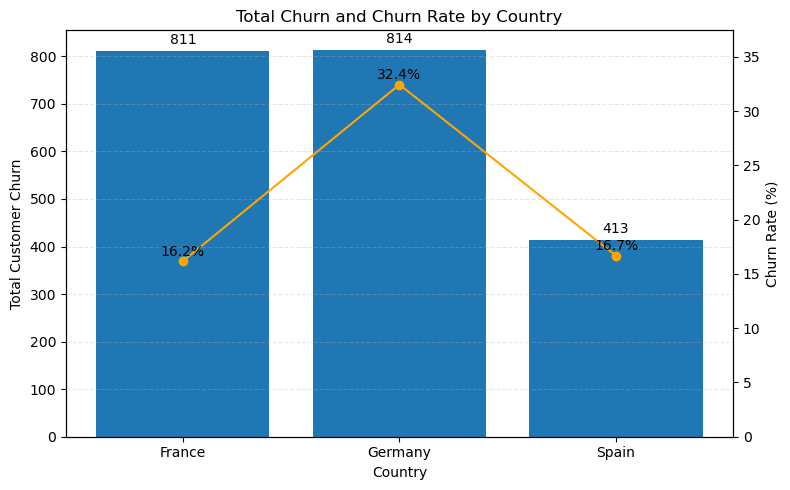

In [ ]:
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar Chart
bars = ax1.bar(
  df_country['Geography'],
  df_country['Total_Churn']
)

ax1.set_ylabel('Total Customer Churn')
ax1.set_xlabel('Country')
ax1.set_title('Total Churn and Churn Rate by Country')
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Line Chart
ax2 = ax1.twinx()

line = ax2.plot(
  df_country['Geography'],
  df_country['Churn_Rate'],
  marker='o',
  color='orange'
)

ax2.set_ylabel('Churn Rate (%)')

# Label

for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 15,
        f'{int(height)}',
        ha='center',
    )


for i, value in enumerate(df_country['Churn_Rate']):
    ax2.text(
        i,
        value + 0.5,
        f'{value:.1f}%',
        ha='center',
    )
ax2.set_ylim(0, max(df_country['Churn_Rate']) + 5)
plt.tight_layout()
plt.show()

**Jerman memiliki customer churn rate hampir 2x lebih tinggi (32.54%) dibandingkan spanyol (16.7%) dan Perancis (16.2%)**, sedangkan Spanyol dan Perancis memiliki nilai yang hampir sama. Beberapa kemungkinannya, yaitu bank kompetitor di Jerman lebih agresif, produk kurang sesuai dengan kebutuhan masyarakat Jerman, dan pricing / fee kurang kompetitif.

**Rekomendasi**

1. Terapkan strategi marketing spesifik untuk Jerman, seperti promo khusus negara Jerman
2. Bandingkan pricing, service quality, atau fitur produk dengan bank lain di Jerman
3. Analisis penyebab nasabah yang memiliki tingkat komplain yang tinggi.

## 4.2 Seberapa besar jumlah produk / layanan yang dimiliki nasabah mempengaruhi tingkat churn? ?

**Kartu Kredit**

In [ ]:
df_credit = df[df['Exited'] == 1].groupby('HasCrCard').size().reset_index(name='Count')

df_credit['HasCrCard'] = df_credit['HasCrCard'].map({
  0:'Tidak Punya',
  1: 'Punya'
})

df_credit

,HasCrCard,Count
0,Tidak Punya,613
1,Punya,1425


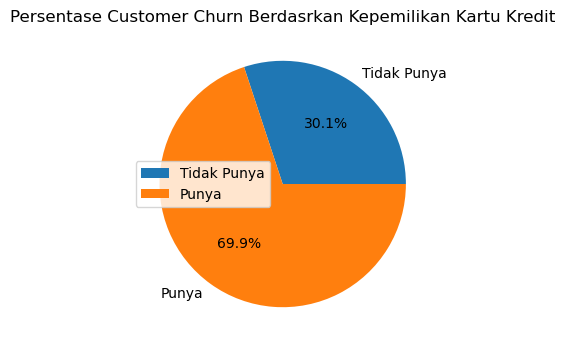

In [ ]:
plt.figure(figsize=(4, 4))
plt.pie(df_credit['Count'], labels=df_credit['HasCrCard'], autopct='%1.1f%%')


plt.title('Persentase Customer Churn Berdasrkan Kepemilikan Kartu Kredit')
plt.legend()
plt.show()

Pada hasil analisis tersebut, disimpulkan bahwa ternyata sebesar 69.9% nasabah yang sudah keluar ternyata memiliki kartu kredit. Hal ini tidak sesuai dengan asumsi awal bahwa nasabah yang memiliki produk atau menggunakan banyak layanan cenderung tidak keluar dari bank. Hal ini kemungkinan disebabkan oleh ketidakpuasan terhadap layanan kartu kredit itu sendiri, seperti bunga tinggi, layanan yang kurang responsif, atau benefit yang tidak kompetitif dibanding kompetitor.

**Rekomendasi**

Lakukan evaluasi menyeluruh terhadap produk kartu kredit yang ditawarkan serta identifikasi keluhan spesifik dari nasabah pemegang kartu kredit yang keluar melalui exit survey.

**Jumlah Produk**

Apakah nasabah yang memiliki banyak produk lebih setia dan tidak rentan keluar ?

In [ ]:
df_product_churn = df.copy()
df_product_churn = df.groupby('NumOfProducts')['Exited'].mean().reset_index()

df_product_churn

,NumOfProducts,Exited
0,1,0.277144
1,2,0.076035
2,3,0.827068
3,4,1.000000


In [ ]:
df[df['Exited']==1].groupby('NumOfProducts').agg({
  'Complain' : 'sum',
  'CustomerId' : 'count'
}).reset_index()


,NumOfProducts,Complain,CustomerId
0,1,1406,1409
1,2,348,349
2,3,220,220
3,4,60,60


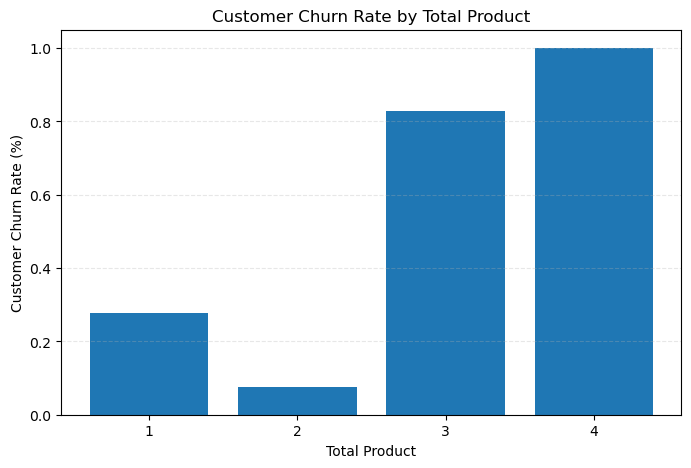

In [ ]:
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar Chart
bars = ax1.bar(
  df_product_churn['NumOfProducts'].astype(str),
  df_product_churn['Exited']
)

ax1.set_ylabel('Customer Churn Rate (%)')
ax1.set_xlabel('Total Product')
ax1.set_title('Customer Churn Rate by Total Product')
ax1.grid(axis='y', linestyle='--', alpha=0.3)

Semakin banyak produk yang dimiliki nasabah justru semakin meningkat tinggi risiko terhadap customer churn. **Dari hasil analisis data menunjukkan hampir semua (>80%) nasabah yang memiliki produk > 2 keluar dari bank dan mengajukan komplain**. Hal ini mengindikasikan bahwa memiliki terlalu banyak produk justru menimbulkan beban finansial atau kompleksitas layanan yang tidak sebanding dengan nilai yang dirasakan nasabah.  

**Rekomendasi**

Memastikan setiap layanan dan produk dapat terintegrasikan dengan baik dan memastikan setiap layanan produk memberikan benefit yang nyata bukan sekadar sebagai beban biaya tambahan. Mengadakan program relationship manager khusus dengan nasabah yang punya produk > 2 agar memastikan nasabah mendapatkan pendampingan dan layanan yang lebih personal sehingga menurunkan kompleksitas produk.

## 4.3 Tren churn rate seperti apa yang muncul seiring bertambahnya tenure nasabah ?

    Tenure    Exited
0        0  0.230024
1        1  0.224155
2        2  0.191794
3        3  0.211100
4        4  0.205258
5        5  0.206522
6        6  0.202689
7        7  0.172179
8        8  0.192195
9        9  0.217480
10      10  0.206122


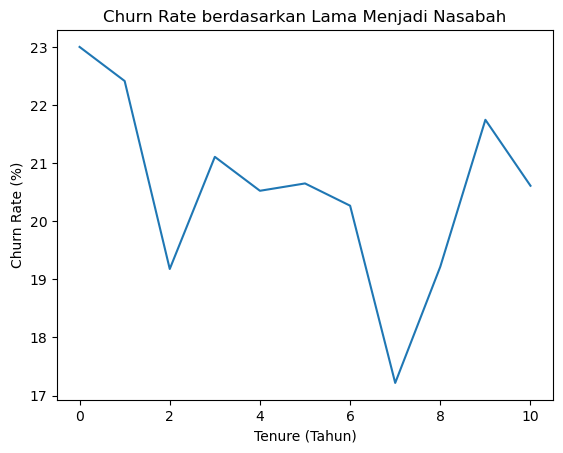

In [ ]:
tenure_churn = (
    df.groupby('Tenure')['Exited']
    .mean()
    .reset_index()
)

print(tenure_churn)
# Plot
plt.figure()
plt.plot(tenure_churn['Tenure'], tenure_churn['Exited']*100)
plt.xlabel('Tenure (Tahun)')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate berdasarkan Lama Menjadi Nasabah')
plt.show()

Dari grafik nasabah baru (tenure = 0 - 1 tahun) dan nasabah lama (tenure = 7 - 10 tahun) yang memiliki churn rate sedikit lebih tinggi dibandingkan tahun - tahun lainnya. Pada nasabah baru, tingkat churn kemungkinan disebabkan karena belum terikat loyalitas maupun finansial yang kuat dengan bank. Sementara, pada nasabah lama kemungkinan disebabkan karena mulai merasa jenuh dan tidak mendapatkan manfaat baru atau tidak dihargai setelah menjadi nasabah setia. Namun perlu diperhatikan bahwa tenure buka satu - satunya penyebab customer churn karena perbedaan persentase customer churn yang tidak terlalu jauh setiap tahun.

**Rekomendasi**

Nasabah baru : Melakukan penguatan program onboarding di 90 hari pertama dengan memberikan promo menarik seperti cashback, bebas biaya admin, atau reward poin agar nasabah bisa langsung merasakan valuenya

Nasabah lama : Melakukan penawaran benefit premium seperti status "Nasabah prioritas" agar mereka merasa dihargai karena loyalitasnya yang cukup lama.

Tambahan : Identifikasi pola perilaku dan produk yang digunakan nasabah pada tenure 7 tahun karena memiliki churn rate yang paling rendah.

## 4.4 Apakah nasabah yang mengajukan komplain memiliki kecenderungan churn yang jauh lebih tinggi dibandingkan yang tidak ?

In [ ]:
# Menghitung Churn Rate Berdasarkan pernah atau tidaknya melakukan komplain
df_complain = df.groupby(['Complain'])['Exited'].agg(['mean', 'sum']).reset_index()
df_complain.columns = ['Complain','Churn Rate','Total Customer Churn']
df_complain

,Complain,Churn Rate,Total Customer Churn
0,0,0.000503,4
1,1,0.995108,2034


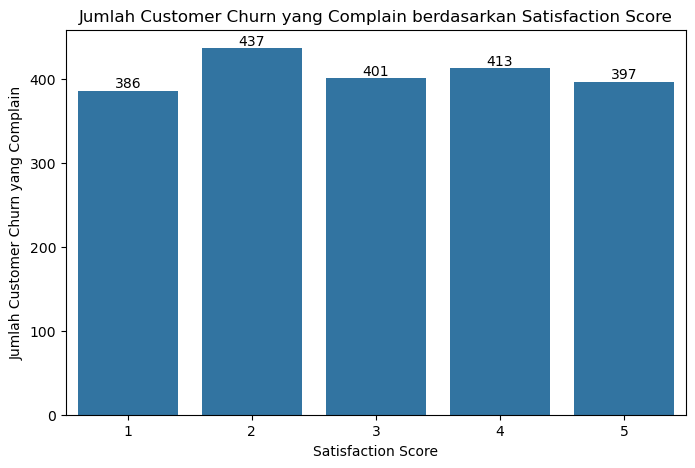

In [ ]:
df_churn_complain = df[(df['Exited'] == 1) & (df['Complain'] == 1)]

plt.figure(figsize=(8,5))

ax = sns.countplot(data=df_churn_complain, x='Satisfaction Score')

# Tambahkan label jumlah di atas bar
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height(),
        int(p.get_height()),
        ha='center',
        va='bottom'
    )

plt.xlabel('Satisfaction Score')
plt.ylabel('Jumlah Customer Churn yang Complain')
plt.title('Jumlah Customer Churn yang Complain berdasarkan Satisfaction Score')

plt.show()

Hasil analisis menunjukkan bahwa nasabah yang keluar dan pernah mengajukan komplain memiliki churn rate (99.5%) artinya komplain merupakan indikasi awal yang kuat untuk memprediksi nasabah yang keluar. Hasil grafik menunjukkan bahwa tidak bahwa masih terdapat banyak komplain pada nasabah walaupun skor kepuasan pelanggan yang tinggi sehingga skor kepuasan tidak bisa dilihat sebagai faktor untuk menentukan customer churn.

**Rekomendasi**

Melakukan pengecekan dan peningkatan kualitas pada tim customer service bagaimana mereka menangani keluhan nasabah. Pastikan setiap komplain tidak hanya ditutup (closed), tapi dipastikan pelanggan puas dengan solusinya. Jika terdeteksi ada kegagalan layanan, berikan voucher, diskon, atau poin loyalitas secara otomatis sebelum mereka merasa kecewa.


## 4.5 Bagaimana pengaruh nasabah yang keluar terhadap keuntungan bank ?

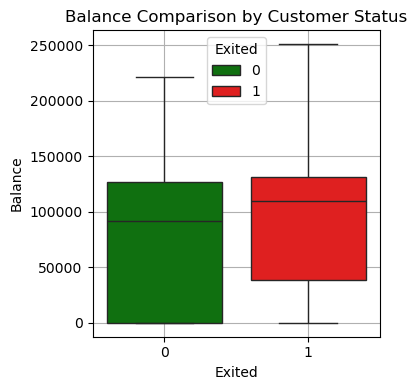

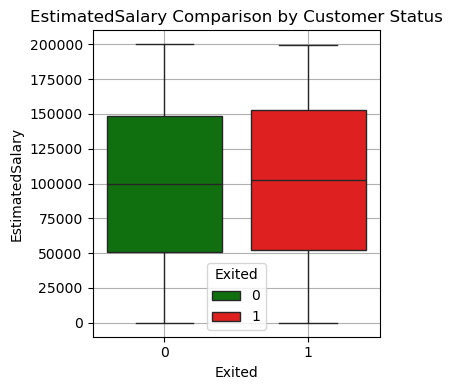

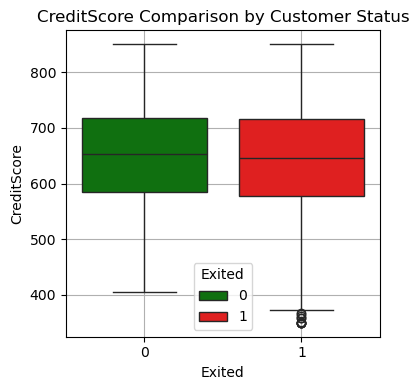

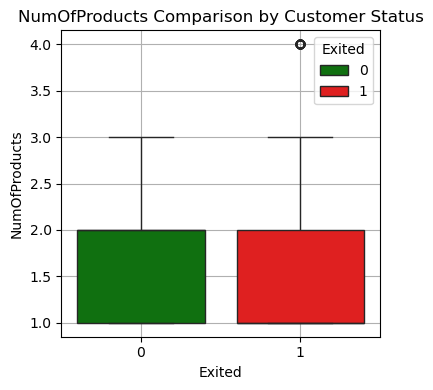

In [ ]:
numerical_cols = ['Balance', 'EstimatedSalary', 'CreditScore', 'NumOfProducts']

for col in numerical_cols:
    plt.figure(figsize=(4, 4))
    sns.boxplot(x='Exited', y=col, data=df, hue='Exited', palette={0: 'green', 1: 'red'})
    plt.title(f'{col} Comparison by Customer Status')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
comparison_table = df.groupby('Exited')[numerical_cols].mean().T
print("Customer Comparison (Exited = 0 vs 1):")
print(comparison_table)

Customer Comparison (Exited = 0 vs 1):
Exited                      0              1
Balance          72742.750663   91109.476006
EstimatedSalary  99726.853141  101509.908783
CreditScore        651.837855     645.414622
NumOfProducts        1.544210       1.475466


Nasabah yang sudah keluar memiliki rata - rata balance yang lebih tinggi (91109.47) dibandingkan nasabah yang bertahan (72742.75). Hal ini mengindikasikan bahwa customer churn dapat berdampak terhadap potensi revenue bank yang berkurang.

**Rekomendasi**

Melakukan peningkatan strategi marketing pada segmen "High Balance Customer" dalam menjaga retention customer untuk menjaga revenue dari bank. Selain itu, pihak bank dapat membuat layanan premium atau benefit eksklusif pada segmen customer High Balance.

## 4.6 Apakah status keaktifan nasabah berpengaruh terhadap kemungkinan nasabah melakukan churn / keluar ?

H0: Tidak terdapat hubungan antara status keaktifan nasabah (IsActiveMember) dan churn (Exited).

H1 : Terdapat hubungan antara status keaktifan nasabah (IsActiveMember) dan churn (Exited).

In [ ]:
from scipy.stats import chi2_contingency

# Buat tabel silang
contingency_table = pd.crosstab(df['IsActiveMember'], df['Exited'])

print(contingency_table)

Exited             0     1
IsActiveMember            
0               3546  1303
1               4416   735


In [ ]:
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 243.6948024819593
p-value: 6.153167438113408e-55
Degrees of freedom: 1


C:\Users\M Rafli F\App Data\Local\Temp\ipykernel_17152\1942679161.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df.pivot_table(


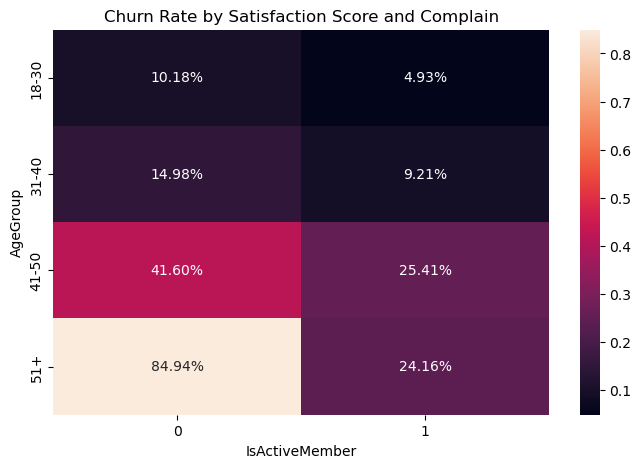

In [ ]:
heatmap_data = df.pivot_table(
    index='AgeGroup',
    columns='IsActiveMember',
    values='Exited',
    aggfunc='mean'
)

plt.figure(figsize=(8,5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2%'
)

plt.title('Churn Rate by Age Group and Active Status')
plt.show()

Berdasarkan uji statistik menunjukkan nilai p-value < 0.05 sehingga H0 ditolak, artinya terdapat hubungan antara status keaktifan nasabah dengan status nasabah yang keluar (churn).

Nasabah tidak aktif (0) usia 51+ memiliki churn rate tertinggi sebesar 84.94% — hampir 3.5x lipat dibanding yang aktif (24.16%) di kelompok usia yang sama. Pola konsisten di semua usia — nasabah tidak aktif selalu churn lebih tinggi dibanding yang aktif, dan churn rate meningkat seiring bertambahnya usia.

**Rekomendasi**

Menjadikan nasabah dengan status tidak aktif sebagai "Early Warning" untuk dasar sistem monitoring churn. Buat reminder penggunaan, notifikasi personal, atau promo akivasi ulang untuk menaikan engagment nasabah yang sudah tidak aktif.

# 5. Feature Engineering

## 5.1 Cardinality Checking

Tahapan ini dilakukan untuk menghapus kolom yang memiliki high cardinality (bersifat sebagai identitas unik) agar tidak mengurangi performa model machine learning

In [6]:
df_fe = df.copy()

# Menampilkan kolom secara penuh tanpa potongan
pd.set_option('display.max_colwidth', None)

# Memperoleh list kolom objek
object_col = list(df_fe.select_dtypes(include='object').columns)

# Membuat dataframe perhitungan cardinality dari setiap kolom kategorik
listItem = []
for col in object_col:
  listItem.append([col, df_fe[col].nunique(), df_fe[col].unique()])

pd.DataFrame(columns=['Column', 'Number of Unique Values', 'Unique Values'], data=listItem)

,Column,Number of Unique Values,Unique Values
0,CustomerId,10000,"[15634602, 15647311, 15619304, 15701354, 15737888, 15574012, 15592531, 15656148, 15792365, 15592389, 15767821, 15737173, 15632264, 15691483, 15600882, 15643966, 15737452, 15788218, 15661507, 15568982, 15577657, 15597945, 15699309, 15725737, 15625047, 15738191, 15736816, 15700772, 15728693, 15656300, 15589475, 15706552, 15750181, 15659428, 15732963, 15794171, 15788448, 15729599, 15717426, 15585768, 15619360, 15738148, 15687946, 15755196, 15684171, 15754849, 15602280, 15771573, 15766205, 15771873, 15616550, 15768193, 15683553, 15702298, 15569590, 15760861, 15630053, 15647091, 15623944, 15804771, 15651280, 15773469, 15702014, 15751208, 15592461, 15789484, 15696061, 15641582, 15638424, 15755648, 15703793, 15620344, 15812518, 15779052, 15770811, 15780961, 15614049, 15662085, 15575185, 15803136, 15706021, 15663706, 15641732, 15701164, 15738751, 15805254, 15762418, 15625759, 15622897, 15767954, 15757535, 15731511, 15809248, 15640635, 15676966, 15699461, 15738721, 15693683, 15604348, 15633059, ...]"
1,Geography,3,"[France, Spain, Germany]"
2,Gender,2,"[Female, Male]"
3,Card Type,4,"[DIAMOND, GOLD, SILVER, PLATINUM]"


Kolom customer id memiliki jumlah yang sama dengan jumlah baris data sehingga kolom ini merupakan identitas unik yang harus dihapus sebelum melakukan data modellling

In [7]:
df_fe = df_fe.drop(columns=['CustomerId'])
df.head()

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


## 5.2 Data Spliting

### 5.2.1 Split Between Features (X) and Target (Y)

In [8]:
X = df_fe.drop(columns=['Exited', 'Complain'])
y = df_fe['Exited']
X

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,1,DIAMOND,300
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,5,PLATINUM,771
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,3,SILVER,564
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,2,GOLD,339


In [ ]:
y

,Exited
0,1
1,0
2,1
3,0
4,0
...,...
9995,0
9996,0
9997,1
9998,1


### 5.2.2 Train Test Split Imbalanced Data

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Train Size : ', X_train.shape)
print('Test Size : ', X_test.shape)

Train Size :  (8000, 13)
Test Size :  (2000, 13)


## 5.3 Handling Outlier

In [10]:
# Memeriksa skewness distribusi dari setiap kolom numerik pada X_train
num_cols = list(X_train.select_dtypes(exclude='object').columns)

listItem = []
for col in num_cols:
  listItem.append([col, round(X_train[col].skew(), 2), np.where(
    (round(X_train[col].skew(), 2) <= 0.5) & (round(X_train[col].skew(), 2) >= -0.5),
    'normal',
    'skewed')])

skewness = pd.DataFrame(columns=['nama kolom', 'nilai skewness', 'distribution'], data=listItem)
skewness

,nama kolom,nilai skewness,distribution
0,CreditScore,-0.08,normal
1,Age,1.04,skewed
2,Tenure,0.01,normal
3,Balance,-0.14,normal
4,NumOfProducts,0.76,skewed
5,HasCrCard,-0.91,skewed
6,IsActiveMember,-0.07,normal
7,EstimatedSalary,0.01,normal
8,Satisfaction Score,-0.00,normal
9,Point Earned,0.02,normal


In [ ]:
column = []
lower_bound = []
upper_bound = []
percent_total_outlier = []

for row in range(0, len(skewness)):
  col = skewness['nama kolom'][row]
  # checking upper and lower boundary
  if skewness['distribution'][row] == 'skewed':
    IQR = X_train[col].quantile(0.75) - X_train[col].quantile(0.25)
    lower_boundary = X_train[col].quantile(0.25) - (IQR * 3)
    upper_boundary = X_train[col].quantile(0.75) + (IQR * 3)
  else:
    lower_boundary = X_train[col].mean() - 3*X_train[col].std()
    upper_boundary = X_train[col].mean() + 3*X_train[col].std()
  # append to list
  column.append(col)
  lower_bound.append(lower_boundary)
  upper_bound.append(upper_boundary)
  totout = ((len(X_train[X_train[col] > upper_boundary]) / len(X_train) * 100) + (len(X_train[X_train[col] < lower_boundary]) / len(X_train) * 100))
  percent_total_outlier.append(totout)

outliers = pd.DataFrame({
    'column': column,
    'upper_boundary': [round(v, 2) for v in upper_bound],
    'lower_boundary': [round(v, 2) for v in lower_bound],
    'percentage_total_outlier': [round(v, 2) for v in percent_total_outlier]
})
outliers.sort_values('percentage_total_outlier', ascending=False)

,column,upper_boundary,lower_boundary,percentage_total_outlier
1,Age,80.00,-4.00,0.12
0,CreditScore,940.74,360.56,0.06
2,Tenure,13.68,-3.66,0.00
3,Balance,263369.23,-110479.88,0.00
4,NumOfProducts,5.00,-2.00,0.00
5,HasCrCard,4.00,-3.00,0.00
6,IsActiveMember,2.02,-0.98,0.00
7,EstimatedSalary,271805.54,-72766.53,0.00
8,Satisfaction Score,7.24,-1.22,0.00
9,Point Earned,1284.33,-72.13,0.00


Kolom **Age** dan **CreditScore** memiliki persentase outlier yang relatif kecil (kurang dari 1%). Oleh karena itu, pada tahap ini tidak dilakukan penghapusan data (*removal*) maupun pembatasan nilai (*capping*) terhadap outlier karena nilai-nilai tersebut masih berpotensi merepresentasikan kondisi customer yang valid. Penanganan tersebut dihindari untuk mencegah hilangnya informasi penting yang dapat memengaruhi performa model.

## 5.4 Column Transformer

Melakukan transformasi pada nilai2 feature, meliputi one hot encode, standarscaler dan handling missing values

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numerical_features = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary',
    'Satisfaction Score',
    'Point Earned'
]

categorical_features = [
    'Geography',
    'Gender',
    'Card Type'
]

binary_features = [
    'HasCrCard',
    'IsActiveMember'
]

transformer = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_features),

        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ))
        ]), categorical_features),

        ('bin', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent'))
        ]), binary_features)
    ],
    remainder='drop'
)


In [18]:
!pip install xgboost

# 6. Model Definition

Menggunakan model Logistic regression, KNN, SVM, Decision Tree, Random Forest, Adaboost

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


In [37]:
pipe_lr = Pipeline(steps=[
    ('preprocessor', transformer),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced'))
])


pipe_svc = Pipeline(steps=[
    ('preprocessor', transformer),
    ('classifier', SVC(random_state=42, class_weight='balanced'))
])

pipe_dt = Pipeline(steps=[
    ('preprocessor', transformer),
    ('classifier', DecisionTreeClassifier(random_state=42, class_weight='balanced'))
])

pipe_rf = Pipeline(steps=[
    ('preprocessor', transformer),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

scale_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

pipe_xgb = Pipeline(steps=[
    ('preprocessor', transformer),
    ('classifier', XGBClassifier(random_state=42, scale_pos_weight=scale_weight, use_label_encoder=False, eval_metric='logloss' ))
])

# 7. Model Training

## 7.1 Logistic Regression

In [22]:
pipe_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary',
                                                   'Satisfaction Score',
                                                   'Point Earned']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender',
                                                   'Card Type']),
                                                 ('bin',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HasCrCard',
                                                   'IsActiveMember'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42))])

## 7.2 SVC

In [23]:
pipe_svc.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary',
                                                   'Satisfaction Score',
                                                   'Point Earned']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender',
                                                   'Card Type']),
                                                 ('bin',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HasCrCard',
                                                   'IsActiveMember'])])),
                ('classifier', SVC(class_weight='balanced', random_state=42))])

## 7.3 Decision Tree

In [24]:
pipe_dt.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary',
                                                   'Satisfaction Score',
                                                   'Point Earned']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender',
                                                   'Card Type']),
                                                 ('bin',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HasCrCard',
                                                   'IsActiveMember'])])),
                ('classifier',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

## 7.4 Random Forest

In [25]:
pipe_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary',
                                                   'Satisfaction Score',
                                                   'Point Earned']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender',
                                                   'Card Type']),
                                                 ('bin',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HasCrCard',
                                                   'IsActiveMember'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

## 7.5 XGBoost

In [38]:
pipe_xgb.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:39:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary',
                                                   'Satisfaction Score',
                                                   'Point Earned']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('e...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

# 8. Model Evaluation

In [28]:
# Import metrics evaluation classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
# Tentukan metrik evaluasi yang ingin dihitung
scoring = ['accuracy', 'precision', 'recall', 'f1']

## 8.1 Logistic Regression

In [29]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Latih (fit) model terlebih dahulu sebelum melakukan evaluasi
pipe_lr.fit(X_train, y_train)

# Definisikan 5-Fold Stratified Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Lakukan Cross-Validation pada training set
cv_results = cross_validate(pipe_lr, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

# Hitung rata-rata metrik dari Cross-Validation
cv_summary = {
    'Accuracy': cv_results['test_accuracy'].mean(),
    'Precision': cv_results['test_precision'].mean(),
    'Recall': cv_results['test_recall'].mean(),
    'F1-Score': cv_results['test_f1'].mean()
}

# Prediksi pada Test Set
y_pred_test = pipe_lr.predict(X_test)

test_summary = {
    'Accuracy': accuracy_score(y_test, y_pred_test),
    'Precision': precision_score(y_test, y_pred_test),
    'Recall': recall_score(y_test, y_pred_test),
    'F1-Score': f1_score(y_test, y_pred_test)
}

# Satukan ke dalam DataFrame untuk perbandingan
comparison_df = pd.DataFrame({
    'Cross-Validation (Mean)': cv_summary,
    'Test Set': test_summary
})

print("=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (LOGISTIC REGRESSION) ===")
display(comparison_df.round(4))

=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (LOGISTIC REGRESSION) ===


,Cross-Validation (Mean),Test Set
Accuracy,0.7098,0.7110
Precision,0.3822,0.3882
Recall,0.6890,0.7230
F1-Score,0.4915,0.5051


In [ ]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1592
           1       0.39      0.72      0.51       408

    accuracy                           0.71      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.80      0.71      0.74      2000



## 8.2 SVC

In [30]:
# Latih (fit) model SVC terlebih dahulu sebelum melakukan evaluasi
pipe_svc.fit(X_train, y_train)

# Definisikan 5-Fold Stratified Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Lakukan Cross-Validation pada training set
cv_results_svc = cross_validate(pipe_svc, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

# Hitung rata-rata metrik dari Cross-Validation
cv_summary_svc = {
    'Accuracy': cv_results_svc['test_accuracy'].mean(),
    'Precision': cv_results_svc['test_precision'].mean(),
    'Recall': cv_results_svc['test_recall'].mean(),
    'F1-Score': cv_results_svc['test_f1'].mean()
}

# Prediksi pada Test Set
y_pred_test_svc = pipe_svc.predict(X_test)

test_summary_svc = {
    'Accuracy': accuracy_score(y_test, y_pred_test_svc),
    'Precision': precision_score(y_test, y_pred_test_svc),
    'Recall': recall_score(y_test, y_pred_test_svc),
    'F1-Score': f1_score(y_test, y_pred_test_svc)
}

# Satukan ke dalam DataFrame untuk perbandingan
comparison_df_svc = pd.DataFrame({
    'Cross-Validation (Mean)': cv_summary_svc,
    'Test Set': test_summary_svc
})

print("=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (SVC) ===")
display(comparison_df_svc.round(4))
print("\n=== CLASSIFICATION REPORT (SVC) ===")
print(classification_report(y_test, y_pred_test_svc))

=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (SVC) ===


,Cross-Validation (Mean),Test Set
Accuracy,0.7955,0.7940
Precision,0.4988,0.4968
Recall,0.7276,0.7598
F1-Score,0.5919,0.6008



=== CLASSIFICATION REPORT (SVC) ===
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      1592
           1       0.50      0.76      0.60       408

    accuracy                           0.79      2000
   macro avg       0.71      0.78      0.73      2000
weighted avg       0.84      0.79      0.81      2000



## 8.3 Decision Tree

In [31]:
# === 1. EVALUASI DECISION TREE ===
# Latih model DT
pipe_dt.fit(X_train, y_train)

# Cross-Validation DT
cv_results_dt = cross_validate(pipe_dt, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
cv_summary_dt = {
    'Accuracy': cv_results_dt['test_accuracy'].mean(),
    'Precision': cv_results_dt['test_precision'].mean(),
    'Recall': cv_results_dt['test_recall'].mean(),
    'F1-Score': cv_results_dt['test_f1'].mean()
}

# Prediksi Test Set DT
y_pred_test_dt = pipe_dt.predict(X_test)
test_summary_dt = {
    'Accuracy': accuracy_score(y_test, y_pred_test_dt),
    'Precision': precision_score(y_test, y_pred_test_dt),
    'Recall': recall_score(y_test, y_pred_test_dt),
    'F1-Score': f1_score(y_test, y_pred_test_dt)
}

comparison_df_dt = pd.DataFrame({
    'Cross-Validation (Mean)': cv_summary_dt,
    'Test Set': test_summary_dt
})

print("=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (DECISION TREE) ===")
display(comparison_df_dt.round(4))
print("\n=== CLASSIFICATION REPORT (DECISION TREE) ===")
print(classification_report(y_test, y_pred_test_dt))


=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (DECISION TREE) ===


,Cross-Validation (Mean),Test Set
Accuracy,0.7939,0.7990
Precision,0.4936,0.5077
Recall,0.4693,0.4828
F1-Score,0.4809,0.4950



=== CLASSIFICATION REPORT (DECISION TREE) ===
              precision    recall  f1-score   support

           0       0.87      0.88      0.87      1592
           1       0.51      0.48      0.49       408

    accuracy                           0.80      2000
   macro avg       0.69      0.68      0.68      2000
weighted avg       0.80      0.80      0.80      2000



## 8.4 Random Forest

In [32]:
# Latih model RF
pipe_rf.fit(X_train, y_train)

# Cross-Validation RF
cv_results_rf = cross_validate(pipe_rf, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
cv_summary_rf = {
    'Accuracy': cv_results_rf['test_accuracy'].mean(),
    'Precision': cv_results_rf['test_precision'].mean(),
    'Recall': cv_results_rf['test_recall'].mean(),
    'F1-Score': cv_results_rf['test_f1'].mean()
}

# Prediksi Test Set RF
y_pred_test_rf = pipe_rf.predict(X_test)
test_summary_rf = {
    'Accuracy': accuracy_score(y_test, y_pred_test_rf),
    'Precision': precision_score(y_test, y_pred_test_rf),
    'Recall': recall_score(y_test, y_pred_test_rf),
    'F1-Score': f1_score(y_test, y_pred_test_rf)
}

comparison_df_rf = pd.DataFrame({
    'Cross-Validation (Mean)': cv_summary_rf,
    'Test Set': test_summary_rf
})

print("=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (RANDOM FOREST) ===")
display(comparison_df_rf.round(4))
print("\n=== CLASSIFICATION REPORT (RANDOM FOREST) ===")
print(classification_report(y_test, y_pred_test_rf))

=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (RANDOM FOREST) ===


,Cross-Validation (Mean),Test Set
Accuracy,0.8602,0.8665
Precision,0.7969,0.8000
Recall,0.4215,0.4608
F1-Score,0.5512,0.5848



=== CLASSIFICATION REPORT (RANDOM FOREST) ===
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1592
           1       0.80      0.46      0.58       408

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000



## 8.5 XGBoost

In [39]:
# === EVALUASI ADABOOST ===
# Latih model AdaBoost
pipe_xgb.fit(X_train, y_train)

# Cross-Validation xgbBoost
cv_results_xgb = cross_validate(pipe_xgb, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
cv_summary_xgb = {
    'Accuracy': cv_results_xgb['test_accuracy'].mean(),
    'Precision': cv_results_xgb['test_precision'].mean(),
    'Recall': cv_results_xgb['test_recall'].mean(),
    'F1-Score': cv_results_xgb['test_f1'].mean()
}

# Prediksi Test Set xgbBoost
y_pred_test_xgb = pipe_xgb.predict(X_test)
test_summary_xgb = {
    'Accuracy': accuracy_score(y_test, y_pred_test_xgb),
    'Precision': precision_score(y_test, y_pred_test_xgb),
    'Recall': recall_score(y_test, y_pred_test_xgb),
    'F1-Score': f1_score(y_test, y_pred_test_xgb)
}

# Satukan ke dalam DataFrame untuk perbandingan
comparison_df_xgb = pd.DataFrame({
    'Cross-Validation (Mean)': cv_summary_xgb,
    'Test Set': test_summary_xgb
})

print("=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (xgbBOOST) ===")
display(comparison_df_xgb.round(4))
print("\n=== CLASSIFICATION REPORT (xgbBOOST) ===")
print(classification_report(y_test, y_pred_test_xgb))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:40:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:40:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:40:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:40:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:

=== PERBANDINGAN CROSS-VALIDATION VS TEST SET (xgbBOOST) ===


,Cross-Validation (Mean),Test Set
Accuracy,0.8270,0.8285
Precision,0.5734,0.5705
Recall,0.5939,0.6446
F1-Score,0.5832,0.6053



=== CLASSIFICATION REPORT (xgbBOOST) ===
              precision    recall  f1-score   support

           0       0.91      0.88      0.89      1592
           1       0.57      0.64      0.61       408

    accuracy                           0.83      2000
   macro avg       0.74      0.76      0.75      2000
weighted avg       0.84      0.83      0.83      2000



In [40]:

# Mengumpulkan metrik evaluasi Test Set untuk setiap model baseline
baseline_comparison = pd.DataFrame({
    'Logistic Regression': test_summary,
    'SVC': test_summary_svc,
    'Decision Tree': test_summary_dt,
    'Random Forest': test_summary_rf,
    'XGBoost': test_summary_xgb
}).T

# Mengumpulkan metrik evaluasi Cross-Validation (Mean) untuk setiap model
cv_comparison = pd.DataFrame({
    'Logistic Regression': cv_summary,
    'SVC': cv_summary_svc,
    'Decision Tree': cv_summary_dt,
    'Random Forest': cv_summary_rf,
    'XGBoost': cv_summary_xgb
}).T

print("=== PERBANDINGAN PERFORMA BASELINE MODEL (TEST SET) ===")
display(baseline_comparison.round(4))

print("\n=== PERBANDINGAN PERFORMA BASELINE MODEL (CROSS-VALIDATION MEAN) ===")
display(cv_comparison.round(4))



=== PERBANDINGAN PERFORMA BASELINE MODEL (TEST SET) ===


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7110,0.3882,0.7230,0.5051
SVC,0.7940,0.4968,0.7598,0.6008
Decision Tree,0.7990,0.5077,0.4828,0.4950
Random Forest,0.8665,0.8000,0.4608,0.5848
XGBoost,0.8285,0.5705,0.6446,0.6053



=== PERBANDINGAN PERFORMA BASELINE MODEL (CROSS-VALIDATION MEAN) ===


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7098,0.3822,0.6890,0.4915
SVC,0.7955,0.4988,0.7276,0.5919
Decision Tree,0.7939,0.4936,0.4693,0.4809
Random Forest,0.8602,0.7969,0.4215,0.5512
XGBoost,0.8270,0.5734,0.5939,0.5832


# 9. Hyperparameter Tuning

## 9.1. SVC

In [36]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Definisikan parameter grid untuk tuning model SVC
param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 'auto'],
    'classifier__kernel': ['rbf', 'linear']
}

# Gunakan StratifiedKFold untuk menjaga distribusi class target
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inisialisasi GridSearchCV dengan fokus optimasi pada F1-Score
grid_search = GridSearchCV(
    estimator=pipe_svc,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Lakukan fitting hyperparameter tuning pada data training
print("Memulai Hyperparameter Tuning untuk pipe_svc...")
grid_search.fit(X_train, y_train)

# Menampilkan parameter terbaik dan best score
best_pipe_svc = grid_search.best_estimator_
print(f"\nBest Hyperparameters: {grid_search.best_params_}")
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

# Evaluasi model terbaik pada Test Set
y_pred_best_svc = best_pipe_svc.predict(X_test)

print("\n=== CLASSIFICATION REPORT (BEST SVC) ===")
print(classification_report(y_test, y_pred_best_svc))

# Simpan summary hasil evaluasi test set
best_svc_summary = {
    'Accuracy': accuracy_score(y_test, y_pred_best_svc),
    'Precision': precision_score(y_test, y_pred_best_svc),
    'Recall': recall_score(y_test, y_pred_best_svc),
    'F1-Score': f1_score(y_test, y_pred_best_svc)
}

df_best_svc_summary = pd.DataFrame([best_svc_summary], index=['Best SVC (Tuned)'])
display(df_best_svc_summary.round(4))

Memulai Hyperparameter Tuning untuk pipe_svc...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Hyperparameters: {'classifier__C': 1, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best CV F1-Score: 0.5963

=== CLASSIFICATION REPORT (BEST SVC) ===
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      1592
           1       0.49      0.75      0.60       408

    accuracy                           0.79      2000
   macro avg       0.71      0.78      0.73      2000
weighted avg       0.84      0.79      0.81      2000



,Accuracy,Precision,Recall,F1-Score
Best SVC (Tuned),0.792,0.4936,0.7549,0.5969


## 9.2 XGBoost

In [41]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Definisikan parameter grid untuk tuning model XGBoost
param_grid_xgb = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.8, 1.0]
}

# Gunakan StratifiedKFold untuk menjaga distribusi class target
cv_xgb = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inisialisasi GridSearchCV dengan fokus optimasi pada F1-Score
grid_search_xgb = GridSearchCV(
    estimator=pipe_xgb,
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=cv_xgb,
    n_jobs=-1,
    verbose=1
)

# Lakukan fitting hyperparameter tuning pada data training
print("Memulai Hyperparameter Tuning untuk pipe_xgb...")
grid_search_xgb.fit(X_train, y_train)

# Menampilkan parameter terbaik dan best score
best_pipe_xgb = grid_search_xgb.best_estimator_
print(f"\nBest Hyperparameters: {grid_search_xgb.best_params_}")
print(f"Best CV F1-Score: {grid_search_xgb.best_score_:.4f}")

# Evaluasi model terbaik pada Test Set
y_pred_best_xgb = best_pipe_xgb.predict(X_test)

print("\n=== CLASSIFICATION REPORT (BEST XGBOOST) ===")
print(classification_report(y_test, y_pred_best_xgb))

# Simpan summary hasil evaluasi test set
best_xgb_summary = {
    'Accuracy': accuracy_score(y_test, y_pred_best_xgb),
    'Precision': precision_score(y_test, y_pred_best_xgb),
    'Recall': recall_score(y_test, y_pred_best_xgb),
    'F1-Score': f1_score(y_test, y_pred_best_xgb)
}

df_best_xgb_summary = pd.DataFrame([best_xgb_summary], index=['Best XGBoost (Tuned)'])
display(df_best_xgb_summary.round(4))

Memulai Hyperparameter Tuning untuk pipe_xgb...
Fitting 5 folds for each of 54 candidates, totalling 270 fits

Best Hyperparameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}
Best CV F1-Score: 0.6088

=== CLASSIFICATION REPORT (BEST XGBOOST) ===
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      1592
           1       0.52      0.77      0.62       408

    accuracy                           0.81      2000
   macro avg       0.73      0.79      0.74      2000
weighted avg       0.85      0.81      0.82      2000



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:41:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,Accuracy,Precision,Recall,F1-Score
Best XGBoost (Tuned),0.8065,0.5172,0.7721,0.6195


# 10. Analisis Kurva ROC-AUC
Bagian ini ditambahkan untuk mengevaluasi kemampuan model dalam memisahkan kelas nasabah yang keluar (*churn*) dan tetap (*loyal*) menggunakan metrik ROC-AUC.

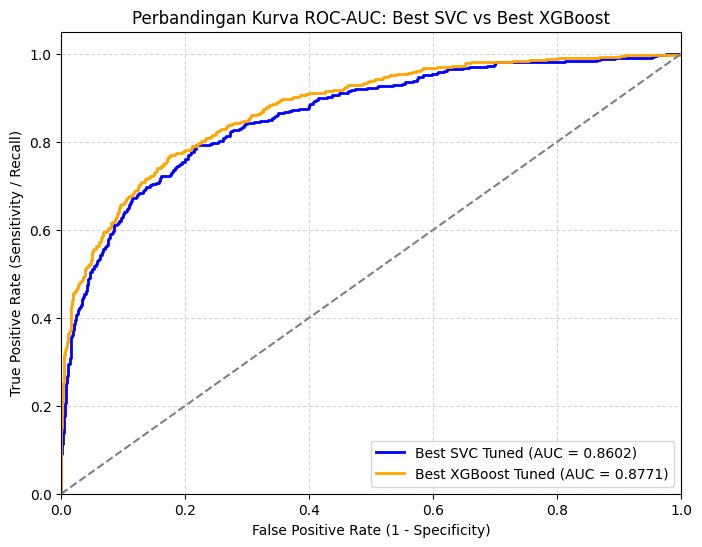

ROC-AUC Score SVC (Tuned)     : 0.8602
ROC-AUC Score XGBoost (Tuned) : 0.8771


In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Dapatkan probabilitas prediksi untuk kelas positif (Exited = 1)
# Untuk SVC, karena class_weight='balanced' dan probability=False secara default,
# kita bisa menggunakan decision_function sebagai skor kepercayaan (confidence scores).
y_score_svc = best_pipe_svc.decision_function(X_test)

# Untuk XGBoost, kita menggunakan predict_proba
y_prob_xgb = best_pipe_xgb.predict_proba(X_test)[:, 1]

# 2. Hitung False Positive Rate (fpr), True Positive Rate (tpr), dan AUC
fpr_svc_tuned, tpr_svc_tuned, _ = roc_curve(y_test, y_score_svc)
auc_svc_tuned = auc(fpr_svc_tuned, tpr_svc_tuned)

fpr_xgb_tuned, tpr_xgb_tuned, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb_tuned = auc(fpr_xgb_tuned, tpr_xgb_tuned)

# 3. Visualisasikan Kurva ROC-AUC
plt.figure(figsize=(8, 6))
plt.plot(fpr_svc_tuned, tpr_svc_tuned, color='blue', lw=2,
         label=f'Best SVC Tuned (AUC = {auc_svc_tuned:.4f})')
plt.plot(fpr_xgb_tuned, tpr_xgb_tuned, color='orange', lw=2,
         label=f'Best XGBoost Tuned (AUC = {auc_xgb_tuned:.4f})')

# Plot garis diagonal (random classifier)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Perbandingan Kurva ROC-AUC: Best SVC vs Best XGBoost')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Tampilkan perbandingan skor AUC secara formal
print(f"ROC-AUC Score SVC (Tuned)     : {auc_svc_tuned:.4f}")
print(f"ROC-AUC Score XGBoost (Tuned) : {auc_xgb_tuned:.4f}")

Kurva **ROC (Receiver Operating Characteristic)** dan skor **AUC (Area Under the Curve)** mengukur kemampuan model dalam membedakan antara nasabah yang akan *churn* (kelas 1) dengan nasabah yang tetap bertahan/loyal (kelas 0) di berbagai ambang batas keputusan (*threshold*).

1. **Kemampuan Diskriminasi Model:**
   * Nilai AUC berkisar dari `0.5` (sama seperti tebakan acak / *random guessing*) hingga `1.0` (klasifikasi sempurna).
   * Kedua model memiliki performa yang sangat kuat di atas **0.85**, menunjukkan bahwa kedua algoritma ini sangat handal dalam memisahkan profil nasabah loyal dengan yang berisiko keluar.

2. **XGBoost Tuned vs SVC Tuned:**
   * **XGBoost (Tuned)** memiliki performa sedikit lebih unggul dengan nilai AUC sekitar **0.8771** dibandingkan dengan **SVC (Tuned)** yang memperoleh nilai AUC sebesar **0.8602**.
   * Secara visual, kurva XGBoost (warna oranye) berada di atas kurva SVC (warna biru) pada hampir seluruh cakupan sumbu, mengonfirmasi bahwa XGBoost secara konsisten menghasilkan *True Positive Rate* (Recall) yang lebih tinggi pada tingkat *False Positive Rate* yang sama.

3. **Kesimpulan untuk Bisnis:**
   * **XGBoost Tuned** adalah model terbaik secara keseluruhan jika kita ingin mencari keseimbangan optimal dalam memprediksi *churn*. Dengan AUC yang lebih tinggi, tim marketing dapat mengatur threshold probabilitas yang lebih fleksibel demi menekan biaya promosi tanpa kehilangan banyak nasabah berisiko tinggi yang seharusnya terdeteksi.

# 11. Feature Importances

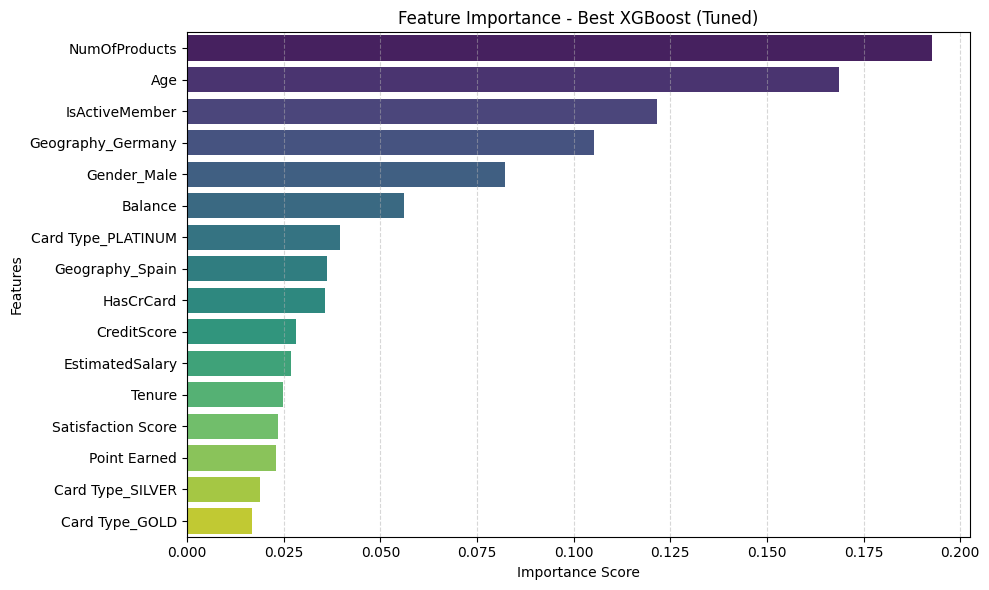

,Feature,Importance
4,NumOfProducts,0.192792
1,Age,0.168697
15,IsActiveMember,0.121551
8,Geography_Germany,0.105240
10,Gender_Male,0.082215
3,Balance,0.056069
12,Card Type_PLATINUM,0.039611
9,Geography_Spain,0.036185
14,HasCrCard,0.035585
0,CreditScore,0.028286


In [47]:
# 1. Ekstrak nama kolom dari preprocessor (transformer)
preprocessor = best_pipe_xgb.named_steps['preprocessor']

# Ambil nama fitur untuk kolom numerik
num_features_out = preprocessor.transformers_[0][2]

# Ambil nama fitur untuk kolom kategorik (One-Hot Encoder)
cat_encoder = preprocessor.transformers_[1][1].named_steps['encoder']
cat_features_out = list(cat_encoder.get_feature_names_out(categorical_features))

# Ambil nama fitur untuk kolom biner
bin_features_out = preprocessor.transformers_[2][2]

# Satukan semua nama fitur sesuai urutan transformasinya
all_features = num_features_out + cat_features_out + bin_features_out

# 2. Ambil feature importances dari XGBoost classifier
xgb_model = best_pipe_xgb.named_steps['classifier']
importances = xgb_model.feature_importances_

# Buat DataFrame untuk mempermudah analisis
feature_importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Visualisasikan Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance - Best XGBoost (Tuned)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Tampilkan dataframe tabelnya
display(feature_importance_df)

# 12. Model Saving

In [48]:
import joblib

# 1. Menyimpan full pipeline (Preprocessor + Model XGBoost yang sudah dituning)
joblib.dump(best_pipe_xgb, 'best_xgboost_pipeline.pkl')

# 2. Menyimpan preprocessor saja (Optional, berguna jika ingin preprocessing terpisah)
joblib.dump(transformer, 'preprocessor_transformer.pkl')

print("Model dan Preprocessor berhasil disimpan!")

Model dan Preprocessor berhasil disimpan!




Untuk menggunakannya kembali (misalnya di script Python atau aplikasi Flask/FastAPI baru), Anda cukup menggunakan kode berikut:

```python
import joblib

# Load pipeline
loaded_pipeline = joblib.load('best_xgboost_pipeline.pkl')

# Langsung gunakan untuk memprediksi data baru tanpa perlu preprocess manual lagi!
# predictions = loaded_pipeline.predict(new_data_raw)
```

### Demonstrasi Penanganan Data Baru dengan Kategori Baru (Unseen Categories)

Mari kita buat data dummy yang mengandung negara baru (`'Indonesia'`) dan jenis kartu baru (`'BRONZE'`) untuk melihat bagaimana pipeline kita menanganinya tanpa error.

# 6. Kesimpulan

### **Kesimpulan Strategis & Rekomendasi Bisnis (Anti-Churn)**

Berdasarkan hasil analisis data (EDA) dan performa model prediksi terbaik (**XGBoost Tuned, AUC = 0.8771**), berikut adalah poin penting serta rekomendasi taktis yang dapat langsung diterapkan oleh Bank XYZ untuk menekan angka *customer churn*:

#### **1. Profil Utama Nasabah yang Rentan Churn (Hasil EDA & Feature Importance)**
* **Jumlah Produk (`NumOfProducts`):** Menjadi fitur paling krusial. Nasabah yang memiliki **lebih dari 2 produk** memiliki *churn rate* sangat ekstrem **(>80%)** dan hampir semuanya mengajukan komplain. Ini mengindikasikan adanya masalah kompleksitas layanan atau biaya administrasi yang menumpuk.
* **Faktor Demografis (Usia & Geografi):**
  * Nasabah berusia **41 tahun ke atas** memiliki tingkat churn yang jauh lebih tinggi (34% - 44.6%).
  * Nasabah dari **Jerman** memiliki risiko churn 2x lipat lebih tinggi (~32.4%) dibandingkan Perancis dan Spanyol.
* **Keaktifan Anggota (`IsActiveMember`):** Nasabah tidak aktif (terutama kelompok usia senior 51+) memiliki rasio churn tertinggi mencapai **84.94%**.
* **Indikator Komplain (`Complain`):** Sebesar **99.5%** nasabah yang keluar sempat melakukan komplain terlebih dahulu. Komplain adalah alarm paling nyata sebelum nasabah benar-benar pergi.

---

#### **2. Solusi & Rekomendasi Aksi untuk Bank XYZ**

| Segmen Target | Masalah Utama | Rekomendasi Tindakan (Action Plan) |
| :--- | :--- | :--- |
| **Nasabah Multi-Produk (>2 Produk)** | Kompleksitas, biaya tinggi, atau layanan tidak terintegrasi. | • Sediakan program *Relationship Manager* khusus untuk mendampingi personal.<br>• Integrasikan tarif administrasi menjadi satu paket hemat (*bundling benefit*). |
| **Nasabah Jerman** | Kompetitor agresif atau ketidakcocokan produk lokal. | • Lakukan *benchmarking* berkala terhadap biaya admin, suku bunga, dan fitur m-banking kompetitor di Jerman.<br>• Rancang kampanye pemasaran lokal yang spesifik. |
| **Nasabah Senior (Usia 41+)** | Kesulitan adaptasi teknologi digital. | • Buat jalur asistensi prioritas di kantor cabang.<br>• Adakan program edukasi berkala yang mudah dipahami terkait penggunaan aplikasi perbankan digital. |
| **Sistem Penanganan Keluhan** | Keluhan tidak diselesaikan dengan tuntas. | • Ubah sistem penanganan komplain: pastikan tiket baru ditutup jika nasabah menyatakan puas secara eksplisit.<br>• Terapkan sistem kompensasi otomatis (misal: pemberian poin loyalitas atau bebas biaya admin 1 bulan) segera setelah nasabah mengalami kegagalan sistem. |
| **Nasabah Tidak Aktif (*Inactive*)** | Kehilangan minat dan interaksi. | • Gunakan prediksi model XGBoost sebagai sistem *Early Warning*.<br>• Kirimkan pesan personalisasi otomatis yang menawarkan promo re-aktivasi (misal: bonus cashback jika bertransaksi kembali). |

---

#### **3. Pemanfaatan Model Machine Learning**
Model **XGBoost yang telah di-tuning** berhasil memisahkan nasabah berisiko dengan akurasi arah yang sangat baik (AUC 0.8771). Tim CRM (Customer Relationship Management) harus mengintegrasikan model ini ke dalam sistem harian untuk menghasilkan daftar nasabah dengan skor probabilitas churn tinggi secara mingguan, sehingga tim marketing dapat melakukan pendekatan preventif sebelum nasabah memutuskan menutup rekening mereka.